True
<class 'pandas.DataFrame'>
RangeIndex: 17536 entries, 0 to 17535
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   date      17536 non-null  datetime64[us]
 1   region    17536 non-null  str           
 2   category  17536 non-null  str           
 3   units     17536 non-null  float64       
 4   sales     17536 non-null  float64       
dtypes: datetime64[us](1), float64(2), str(2)
memory usage: 685.1 KB
None


<Axes: title={'center': 'CA mensuel'}, xlabel='mois'>

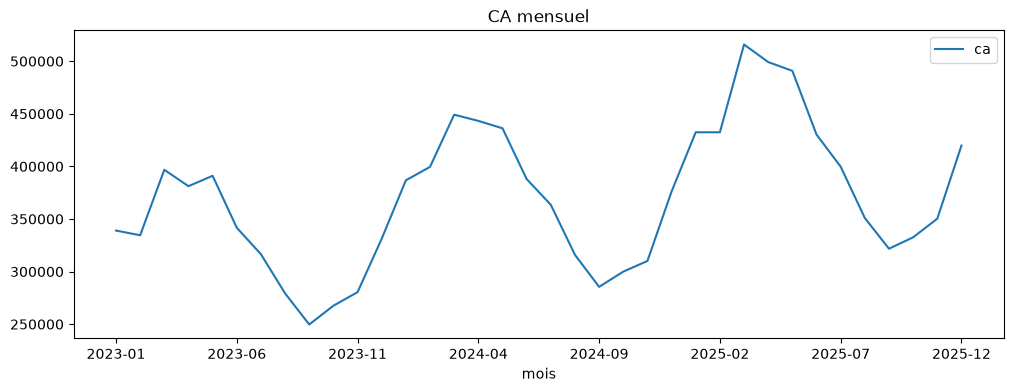

In [1]:
import pandas as pd
import sqlite3
from pathlib import Path

ROOT = Path(r"C:\Users\beche\sales-forecast-platform")
print((ROOT / "data" / "raw" / "sales.csv").exists())

df = pd.read_csv(ROOT / "data" / "raw" / "sales.csv", parse_dates=["date"])
print(df.info())

conn = sqlite3.connect(ROOT / "data" / "sales.db")
df.to_sql("sales", conn, if_exists="replace", index=False)

q = """
SELECT strftime('%Y-%m', date) AS mois, SUM(sales) AS ca
FROM sales
GROUP BY mois
ORDER BY mois
"""
monthly = pd.read_sql(q, conn)
monthly.plot(x="mois", y="ca", figsize=(12, 4), title="CA mensuel")

In [2]:
print(pd.read_sql("""
SELECT category, ROUND(SUM(sales)) AS ca
FROM sales GROUP BY category ORDER BY ca DESC
""", conn))

print(pd.read_sql("""
SELECT region, ROUND(SUM(sales)) AS ca
FROM sales GROUP BY region ORDER BY ca DESC
""", conn))

       category         ca
0  Électronique  8020499.0
1      Mobilier  3571123.0
2     Vêtements  1398118.0
3   Alimentaire   349302.0
   region         ca
0   Tunis  3837307.0
1  Nabeul  3568474.0
2  Sousse  3000881.0
3    Sfax  2932379.0


In [2]:
import sys
from pathlib import Path

ROOT = Path(r"C:\Users\beche\sales-forecast-platform")
sys.path.append(str(ROOT))

from src.features import load_data, add_features, time_split

data = add_features(load_data())
train, test = time_split(data)
print(data.shape, train.shape, test.shape)
data.head()

(17088, 16) (11248, 16) (5840, 16)


,date,region,category,units,sales,year,month,dayofweek,weekofyear,is_weekend,lag_1,lag_7,lag_14,lag_28,roll_mean_7,roll_mean_28
0,2023-01-29,Nabeul,Alimentaire,3.0,73.28,2023,1,6,4,1,76.42,49.79,75.72,75.85,72.185714,69.538214
1,2023-01-30,Nabeul,Alimentaire,3.0,77.74,2023,1,0,5,0,73.28,73.17,78.15,73.70,75.541429,69.446429
2,2023-01-31,Nabeul,Alimentaire,4.0,104.09,2023,1,1,5,0,77.74,76.31,73.39,73.68,76.194286,69.590714
3,2023-02-01,Nabeul,Alimentaire,3.0,75.98,2023,2,2,5,0,104.09,77.08,72.38,77.46,80.162857,70.676786
4,2023-02-02,Nabeul,Alimentaire,3.0,76.19,2023,2,3,5,0,75.98,78.28,72.16,50.80,80.005714,70.623929


In [3]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

# 'units' est exclu : il est connu en même temps que 'sales' (fuite de données)
DROP = ["date", "sales", "units", "year"]
X_all = pd.get_dummies(data.drop(columns=DROP), columns=["region", "category"], dtype=int)
y_all = data["sales"]

is_train = data["date"] < "2025-01-01"
X_train, X_test = X_all[is_train], X_all[~is_train]
y_train, y_test = y_all[is_train], y_all[~is_train]

models = {
    "Baseline (J-7)": None,
    "Régression linéaire": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=300, learning_rate=0.05, random_state=42, verbose=-1),
}

results, preds = [], {}
for name, model in models.items():
    if model is None:
        y_pred = X_test["lag_7"].values
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
    preds[name] = y_pred
    results.append({
        "Modèle": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "MAPE %": mean_absolute_percentage_error(y_test, y_pred) * 100,
    })

pd.DataFrame(results).sort_values("MAE").round(2)

,Modèle,MAE,RMSE,MAPE %
4,LightGBM,83.79,163.73,10.14
2,Random Forest,84.12,161.01,10.47
3,XGBoost,84.60,163.02,10.22
1,Régression linéaire,87.41,158.32,13.75
0,Baseline (J-7),106.85,201.98,13.09


In [6]:
df_all = load_data()
g = df_all.groupby(["region", "category"])["sales"]

df_all["recent7"] = g.transform(lambda s: s.rolling(7).mean())
df_all["ref28"] = g.transform(lambda s: s.shift(7).rolling(28).mean())
df_all["ratio"] = df_all["recent7"] / df_all["ref28"]
df_all["alert"] = df_all["ratio"] < 0.75

# Regrouper les jours d'alerte consécutifs en épisodes
alerts = df_all[df_all["alert"]].copy()
alerts["gap"] = alerts.groupby(["region", "category"])["date"].diff().dt.days.ne(1)
alerts["episode"] = alerts.groupby(["region", "category"])["gap"].cumsum()

summary = (alerts.groupby(["region", "category", "episode"])
           .agg(debut=("date", "min"), fin=("date", "max"), ratio_min=("ratio", "min"))
           .reset_index().drop(columns="episode"))
summary["ratio_min"] = summary["ratio_min"].round(2)

# Filtre : on garde seulement les baisses d'au moins 5 jours
summary["jours"] = (summary["fin"] - summary["debut"]).dt.days + 1
summary = summary[summary["jours"] >= 5]
summary

,region,category,debut,fin,ratio_min,jours
2,Sfax,Mobilier,2025-06-03,2025-06-21,0.44,19


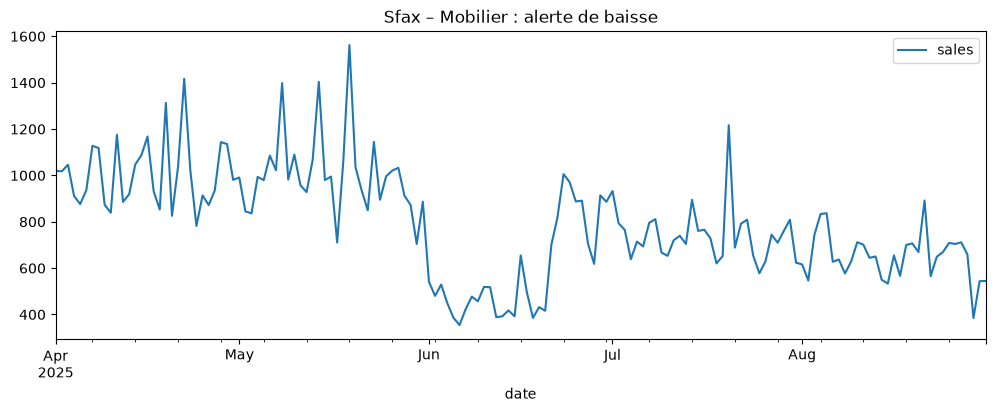

In [5]:
s = df_all[(df_all.region == "Sfax") & (df_all.category == "Mobilier")
           & (df_all.date >= "2025-04-01") & (df_all.date <= "2025-08-31")]
ax = s.plot(x="date", y="sales", figsize=(12, 4), title="Sfax – Mobilier : alerte de baisse")
ax.fill_between(s["date"], s["sales"].min(), s["sales"].max(),
                where=s["alert"].values, color="red", alpha=0.2)